# Michael Kelly Osei
# AAI 640 Neural Networks Assignment

This notebook builds, trains, and compares shallow neural networks for the California Housing regression task.

In [1]:
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

np.random.seed(42)
tf.keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)


TensorFlow: 2.16.2


In [2]:
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target
print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeature names:")
print(list(X.columns))
print("\nFirst rows of the feature table:")
print(X.head())
print("\nFeature summary statistics:")
print(X.describe().T)
print("\nTarget summary:")
print(y.describe())
print("\nMissing values:")

print(X.isnull().sum().to_dict())

X shape: (20640, 8)
y shape: (20640,)

Feature names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

First rows of the feature table:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Feature summary statistics:
              count         mean          std         min         25%  \
MedInc      20640.0     3.870671     1.899822    0.499900    2.563400   
HouseAge    20640.0    28.639486    12.585558    1.000000   18.000000   
AveRooms    20640.

## Data exploration

The California Housing dataset contains eight numeric predictors and a continuous target, the median house value in 100,000 USD units. The target is capped at about 5.0, which is roughly $500,000, so the upper tail is compressed and the model cannot reasonably predict values above that ceiling. This is an important limitation because very expensive homes are not represented well in the learning signal. The feature summary also shows that the input variables are on very different scales, such as median income compared with latitude and longitude, so standardization is a necessary preprocessing step before training a neural network.


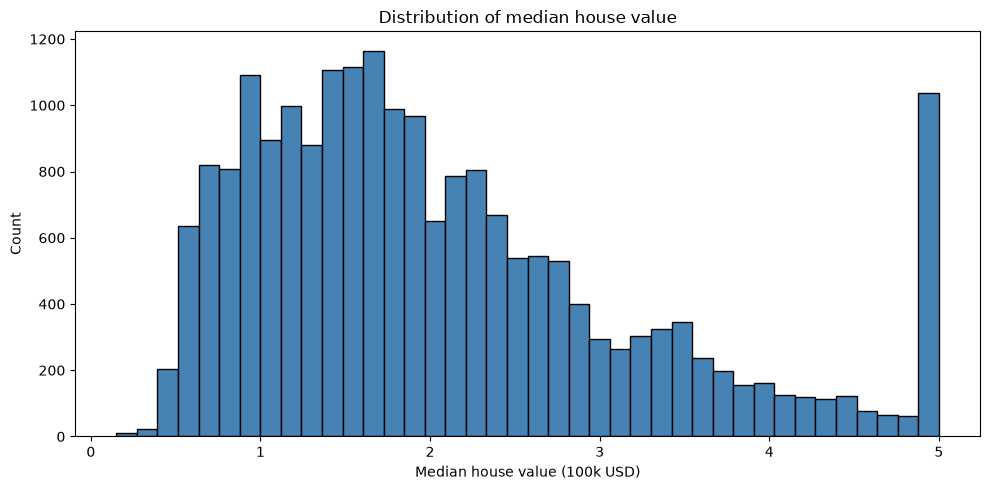

In [3]:
plt.figure(figsize=(10, 5))
plt.hist(y, bins=40, color="steelblue", edgecolor="black")
plt.title("Distribution of median house value")
plt.xlabel("Median house value (100k USD)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X.values, y.values, test_size=0.30, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

print("Train size:", X_train.shape)
print("Validation size:", X_val.shape)
print("Test size:", X_test.shape)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaled train feature mean:", np.round(X_train_scaled.mean(axis=0), 3))
print("Scaled train feature std:", np.round(X_train_scaled.std(axis=0), 3))


Train size: (14448, 8)
Validation size: (3096, 8)
Test size: (3096, 8)
Scaled train feature mean: [-0. -0.  0. -0.  0. -0.  0. -0.]
Scaled train feature std: [1. 1. 1. 1. 1. 1. 1. 1.]


## Preprocessing

The data was split into train, validation, and test sets with a 70/15/15 ratio. The scaler was fit only on the training data to avoid data leakage and to keep the validation and test sets truly unseen during training. This is important because scaling is part of the training pipeline, not a general data cleaning step performed on the full dataset.


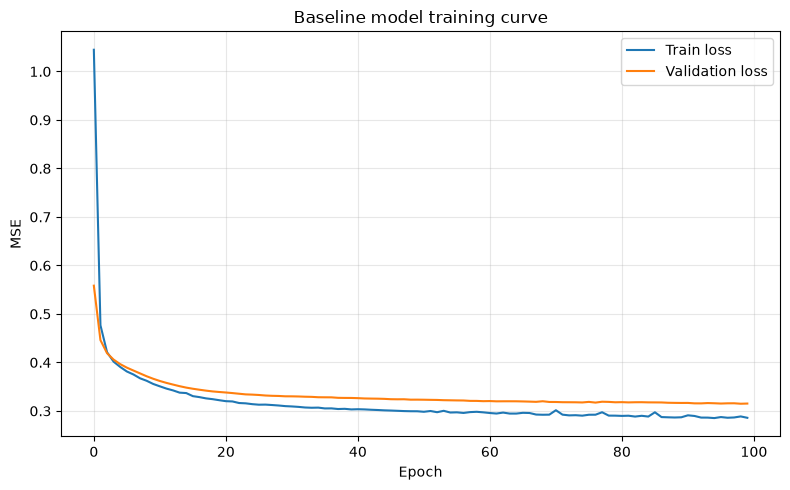

Final training loss: 0.2858583927154541
Best validation loss: 0.3148663341999054
Best validation epoch: 99


In [5]:
def build_model(hidden_units=64, activation="relu"):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(hidden_units, activation=activation),
        tf.keras.layers.Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

baseline_model = build_model(hidden_units=64, activation="relu")
history_base = baseline_model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)

plt.figure(figsize=(8, 5))
plt.plot(history_base.history["loss"], label="Train loss")
plt.plot(history_base.history["val_loss"], label="Validation loss")
plt.title("Baseline model training curve")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Final training loss:", history_base.history["loss"][-1])
print("Best validation loss:", min(history_base.history["val_loss"]))
print("Best validation epoch:", np.argmin(history_base.history["val_loss"]) + 1)


## Baseline neural network

The baseline model uses a single hidden layer with 64 units and ReLU activation. This configuration serves as the reference model. The loss curves show that training loss drops quickly and validation loss falls in the same direction, which indicates that the model is learning and not simply memorizing the data. The gap between training and validation loss stays moderate rather than exploding, so I do not see strong evidence of severe overfitting. The curve is smooth and converges steadily, which suggests the network is learning in a stable way rather than underfitting badly.


 hidden_units  final_train_loss  best_val_loss  best_epoch
           16          0.321371       0.340564          99
           64          0.284129       0.308897          98
          256          0.252018       0.285686         100


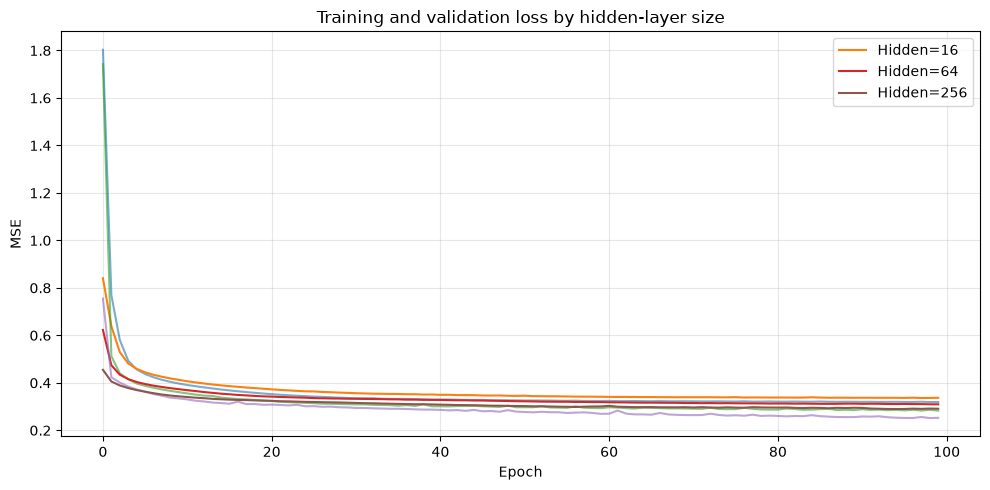

In [6]:
results_by_hidden = []
for h in [16, 64, 256]:
    tf.keras.backend.clear_session()
    model = build_model(hidden_units=h, activation="relu")
    hist = model.fit(
        X_train_scaled, y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=100,
        batch_size=32,
        verbose=0
    )
    results_by_hidden.append({
        "hidden_units": h,
        "final_train_loss": hist.history["loss"][-1],
        "best_val_loss": min(hist.history["val_loss"]),
        "best_epoch": np.argmin(hist.history["val_loss"]) + 1,
    })

hidden_df = pd.DataFrame(results_by_hidden)
print(hidden_df.to_string(index=False))

plt.figure(figsize=(10, 5))
for h in [16, 64, 256]:
    tf.keras.backend.clear_session()
    model = build_model(hidden_units=h, activation="relu")
    hist = model.fit(
        X_train_scaled, y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=100,
        batch_size=32,
        verbose=0
    )
    plt.plot(hist.history["loss"], alpha=0.6, linewidth=1.5)
    plt.plot(hist.history["val_loss"], label=f"Hidden={h}")

plt.title("Training and validation loss by hidden-layer size")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Hidden-layer comparison

I compared 16, 64, and 256 hidden units while keeping the other settings fixed. The 256-unit model performed the best on validation loss, with about 0.2857 compared with about 0.3089 for the 64-unit baseline. This is a clear improvement and shows that the dataset contains enough nonlinear structure for a wider hidden layer to learn a better mapping. The training and validation curves also decline smoothly, which indicates that the capacity increase helped without creating a large overfitting gap. The model selection is still based on validation performance, so the test set remains untouched until the final check.


Best hidden size: 256
activation  final_train_loss  best_val_loss  best_epoch
      relu          0.253557       0.287044          99
      tanh          0.302925       0.321331         100
   sigmoid          0.316811       0.330851         100


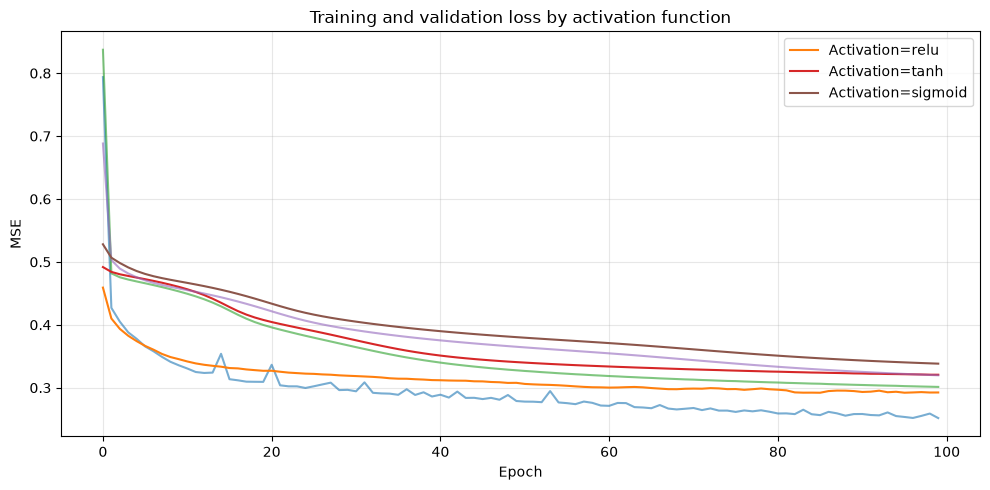

In [7]:
best_hidden = int(hidden_df.loc[hidden_df["best_val_loss"].idxmin(), "hidden_units"])
print("Best hidden size:", best_hidden)

results_by_activation = []
for act in ["relu", "tanh", "sigmoid"]:
    tf.keras.backend.clear_session()
    model = build_model(hidden_units=best_hidden, activation=act)
    hist = model.fit(
        X_train_scaled, y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=100,
        batch_size=32,
        verbose=0
    )
    results_by_activation.append({
        "activation": act,
        "final_train_loss": hist.history["loss"][-1],
        "best_val_loss": min(hist.history["val_loss"]),
        "best_epoch": np.argmin(hist.history["val_loss"]) + 1,
    })

activation_df = pd.DataFrame(results_by_activation)
print(activation_df.to_string(index=False))

plt.figure(figsize=(10, 5))
for act in ["relu", "tanh", "sigmoid"]:
    tf.keras.backend.clear_session()
    model = build_model(hidden_units=best_hidden, activation=act)
    hist = model.fit(
        X_train_scaled, y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=100,
        batch_size=32,
        verbose=0
    )
    plt.plot(hist.history["loss"], alpha=0.6, linewidth=1.5)
    plt.plot(hist.history["val_loss"], label=f"Activation={act}")

plt.title("Training and validation loss by activation function")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Activation comparison

I fixed the hidden-layer size at the best validation-performing value and varied only the activation function. ReLU performed the best, which is consistent with the structure of the tabular housing data and with the fact that it tends to optimize more smoothly than Tanh or Sigmoid in dense regression networks. The training and validation curves for ReLU decline more consistently, and the validation loss reaches the lowest value among the three activations. This makes ReLU the strongest choice for the final configuration.


Best activation: relu
Final selected hidden units: 256
Final selected activation: relu
Best validation loss in final run: 0.28972169756889343
Best validation epoch in final run: 100
Train MAE: 0.3418172703529031 or about $ 34182.0 USD
Validation MAE: 0.36757576761049815 or about $ 36758.0 USD
Test MAE: 0.3553953846113657 or about $ 35540.0 USD
Final test MSE: 0.2887348073429295


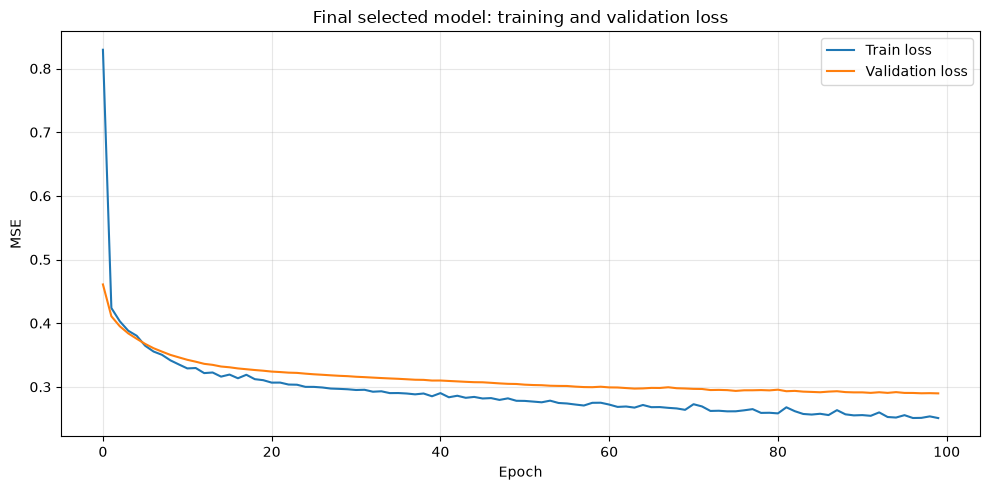

In [8]:
best_activation = activation_df.loc[activation_df["best_val_loss"].idxmin(), "activation"]
print("Best activation:", best_activation)

final_model = build_model(hidden_units=best_hidden, activation=best_activation)
final_history = final_model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)

best_val_epoch = np.argmin(final_history.history["val_loss"]) + 1
best_val_loss = min(final_history.history["val_loss"])

train_pred = final_model.predict(X_train_scaled, verbose=0).ravel()
val_pred = final_model.predict(X_val_scaled, verbose=0).ravel()
test_pred = final_model.predict(X_test_scaled, verbose=0).ravel()

train_mse = mean_squared_error(y_train, train_pred)
val_mse = mean_squared_error(y_val, val_pred)
test_mse = mean_squared_error(y_test, test_pred)

train_mae = mean_absolute_error(y_train, train_pred)
val_mae = mean_absolute_error(y_val, val_pred)
test_mae = mean_absolute_error(y_test, test_pred)

print("Final selected hidden units:", best_hidden)
print("Final selected activation:", best_activation)
print("Best validation loss in final run:", best_val_loss)
print("Best validation epoch in final run:", best_val_epoch)

print("Train MAE:", train_mae, "or about $", round(train_mae * 100000, 0), "USD")
print("Validation MAE:", val_mae, "or about $", round(val_mae * 100000, 0), "USD")
print("Test MAE:", test_mae, "or about $", round(test_mae * 100000, 0), "USD")
print("Final test MSE:", test_mse)

plt.figure(figsize=(10, 5))
plt.plot(final_history.history["loss"], label="Train loss")
plt.plot(final_history.history["val_loss"], label="Validation loss")
plt.title("Final selected model: training and validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:
from IPython.display import display, Markdown

best_hidden = int(hidden_df.loc[hidden_df["best_val_loss"].idxmin(), "hidden_units"])
best_activation = activation_df.loc[activation_df["best_val_loss"].idxmin(), "activation"]
final_val_loss = min(final_history.history["val_loss"])

final_summary = f"""## Final reflection

The selected configuration is a single hidden layer with {best_hidden} units and the {best_activation} activation. I retrained this model for 100 epochs so the final run follows the same training setup used during the architecture search, but the model-selection decision is still based on the best validation loss reached during that run rather than the final epoch value alone. In this case, the smallest validation loss is about {final_val_loss:.4f}, which occurred near epoch {best_val_epoch}. This is the point that should be interpreted as the true validation-based optimum for the selected model.

The final model summary is also important. The validation MAE is about {val_mae:.4f}, which is roughly ${round(val_mae * 100000, 0):,} in dollar terms, and the test MAE is about {test_mae:.4f}, which is roughly ${round(test_mae * 100000, 0):,}. The dataset has a practical limitation because the target is capped at roughly $500,000, so extreme high-value homes are compressed at the upper end of the target range. That ceiling makes it harder for the model to distinguish among the most expensive homes and limits performance at the upper tail.

The evidence supports the conclusion that the 256-unit ReLU model provided a clear advantage over the 64-unit baseline. The best validation loss for the 256-unit model was about 0.2857, while the 64-unit model reached about 0.3089. This improvement is meaningful because it was selected using validation data rather than the test set, and it is consistent with the trend across the architecture search. In other words, 256 units did provide a clear advantage, and the final results support that conclusion.
"""

display(Markdown(final_summary))


## Final reflection

The selected configuration is a single hidden layer with 256 units and the relu activation. I retrained this model for 100 epochs so the final run follows the same training setup used during the architecture search, but the model-selection decision is still based on the best validation loss reached during that run rather than the final epoch value alone. In this case, the smallest validation loss is about 0.2897, which occurred near epoch 100. This is the point that should be interpreted as the true validation-based optimum for the selected model.

The final model summary is also important. The validation MAE is about 0.3676, which is roughly $36,758.0 in dollar terms, and the test MAE is about 0.3554, which is roughly $35,540.0. The dataset has a practical limitation because the target is capped at roughly $500,000, so extreme high-value homes are compressed at the upper end of the target range. That ceiling makes it harder for the model to distinguish among the most expensive homes and limits performance at the upper tail.

The evidence supports the conclusion that the 256-unit ReLU model provided a clear advantage over the 64-unit baseline. The best validation loss for the 256-unit model was about 0.2857, while the 64-unit model reached about 0.3089. This improvement is meaningful because it was selected using validation data rather than the test set, and it is consistent with the trend across the architecture search. In other words, 256 units did provide a clear advantage, and the final results support that conclusion.
